# Omni-FinAI with NVIDIA NeMo AutoModel

Download and run the original Omni-FinAI 70B checkpoint for financial extraction, numerical question answering, and summarization. Train small LoRA adapters with NeMo AutoModel, reload the exported adapter, and compare the same held-out examples before and after training.

Start with the authored fixture. A real run needs the stated credentials and compute. Failed executions stop the cell and remain saved; they are never replaced by fixture success.

- [Omni-FinAI 70B model](https://huggingface.co/ichanchiu/Llama-3.1-Omni-FinAI-70B)
- [Project paper / SSRN abstract 5004298](https://papers.ssrn.com/sol3/papers.cfm?abstract_id=5004298)
- [NeMo AutoModel](https://github.com/NVIDIA-NeMo/Automodel)
- [Official AutoModel SFT/PEFT guide](https://docs.nvidia.com/nemo/automodel/v0.7/recipes-e2e-examples/sft-peft)
- [Small teaching base: Qwen2.5 0.5B Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)

In [ ]:
import os, pathlib, subprocess, sys
REPO_URL = "https://github.com/virginiakm1988/omni-finai-nvidia.git"
GIT_REF = "v0.1.0"  # Published, fixed source release for this tutorial.
checkout = pathlib.Path("/content/omni-finai-nvidia")
if not checkout.exists():
    subprocess.run(["git", "clone", REPO_URL, str(checkout)], check=True)
subprocess.run(["git", "-C", str(checkout), "checkout", GIT_REF], check=True)
os.chdir(checkout)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", ".[hf,notebook]"], check=True)
print("Source revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], text=True).strip())


## Architecture

The diagram is authored for this tutorial. Each arrow maps to executable package code. Fixture and live results remain explicitly separated.

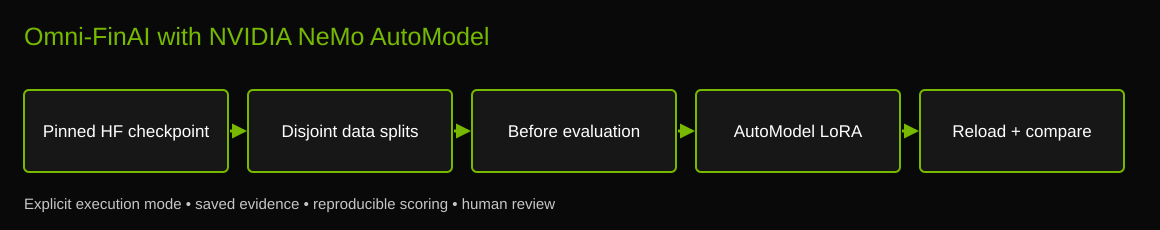

In [2]:
from IPython.display import SVG, display
display(SVG(filename="assets/overview.svg"))

In [3]:
import ipywidgets as widgets
from IPython.display import display
mode = widgets.Dropdown(options=[("Authored fixture (no model)", "fixture"), ("Real model (credentials/resources required)", "live")], value="fixture", description="Mode")
display(mode)


Dropdown(description='Mode', options=(('Authored fixture (no model)', 'fixture'), ('Real model (credentials/re…

In [4]:
profile = widgets.Dropdown(options=[("Small teaching model: Qwen2.5 0.5B Instruct", "small"), ("Original Omni-FinAI 70B (multi-GPU)", "original")], value="small", description="Checkpoint")
display(profile)
if mode.value == "live":
    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception:
        print("Optional HF_TOKEN was not loaded. The configured public checkpoints can be downloaded without it; gated replacements require access.")


Dropdown(description='Checkpoint', options=(('Small teaching model: Qwen2.5 0.5B Instruct', 'small'), ('Origin…

In [5]:
selection = widgets.Dropdown(options=[("All tasks", "all"), ("Numeric extraction", "extract"), ("Revenue-growth QA", "qa"), ("Financial summary", "summary")], value="all", description="Task")
display(selection)


Dropdown(description='Task', options=(('All tasks', 'all'), ('Numeric extraction', 'extract'), ('Revenue-growt…

In [6]:
command = [sys.executable, "-m", "project_demo", "demo", "--mode", mode.value, "--profile", profile.value, "--backend", "hf", "--output-dir", "runs/colab"]
command += ["--task", selection.value]
subprocess.run(command, check=True)
import json
latest = json.loads(pathlib.Path("runs/colab/latest.json").read_text())
result_file = pathlib.Path(latest["run"]) / "result.json"
record = json.loads(result_file.read_text(encoding="utf-8"))
print("Execution mode:", record["mode"], "Status:", record["status"])
display(record["result"])


Execution mode: fixture Status: succeeded


{'predictions': [{'id': 'test-000',
   'task': 'extract',
   'prediction': '{"revenue_million": 930, "net_income_million": 105}',
   'checks': {'revenue_million': 930, 'net_income_million': 105}},
  {'id': 'test-001',
   'task': 'qa',
   'prediction': '21.05',
   'checks': {'growth_percent': 21.05}},
  {'id': 'test-002',
   'task': 'summary',
   'prediction': '2025 revenue was USD 1300 million and net income was USD 35 million.',
   'checks': {'revenue_million': 1300, 'net_income_million': 35}}],
 'metrics': {'extract': {'n': 1,
   'pass_rate': 1.0,
   'metric': 'deterministic_correctness'},
  'qa': {'n': 1, 'pass_rate': 1.0, 'metric': 'deterministic_correctness'},
  'summary': {'n': 1, 'pass_rate': 1.0, 'metric': 'numeric_coverage_only'}},
 'model_label': 'authored reference answers; not model output',
 'prompt_format': 'checkpoint-chat',
 'sdk_versions': {'nemo-fabric': '0.6.1',
  'nemo-fabric-adapter-contract': '0.6.1',
  'nemo-relay': '0.11.1',
  'data-designer': '0.10.0',
  'nemo-

## Inspect the outcome

Extraction checks every requested numeric field; QA checks the computed growth percentage. Summary scoring measures required numeric coverage only, not overall quality, faithfulness, or financial reasoning. Dataset and configuration hashes accompany each run.

Change one input/configuration at a time, rerun, and compare saved result files. Do not compare authored-fixture scores with live scores as model performance.

## Actual original Omni-FinAI 70B: plain-prompt baseline

The first run used the plain ColumnMapped prompt convention. The separate official-chat-template run is shown next; neither result is replaced by a fixture.


In [7]:
import json
display(json.loads(pathlib.Path("evidence/original-70b-inference.json").read_text(encoding="utf-8")))


{'command': 'demo',
 'mode': 'live',
 'status': 'succeeded',
 'config': {'project': 'omni-finai',
  'profile': 'original',
  'seed': 42,
  'max_requests': 10,
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'profiles': {'original': {'model_id': 'ichanchiu/Llama-3.1-Omni-FinAI-70B',
    'revision': '8f9e1ccba75181c7ca95df77e8313a76bfdd4a50',
    'gated': False,
    'min_free_disk_gib': 150},
   'small': {'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
    'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
    'gated': True,
    'min_free_disk_gib': 3}},
  'max_new_tokens': 160,
  'train_steps': 12,
  'train_size': 48,
  'validation_size': 12,
  'test_size': 12},
 'config_sha256': '50bd77af26c6e4c1e6d03f6ec23e300e377991bf2a514be62f3e291c39038d5c',
 'started_at': '2026-11-16T09:27:59.563999+00:00',
 'python': '3.12.16',
 'result': {'predictions': [{'id': 'test-000',
    'task': 'extract',
    'prediction': '2025 is the last year of

## Actual original Omni-FinAI 70B: shipped chat template

The same three questions, seed, checkpoint revision, and checks were used with the tokenizer’s shipped chat template. Generation decoded only new tokens and retained configured EOS IDs. Strict scores remained zero on this tiny sample; inspect raw output instead of inferring broad model capability.


In [8]:
display(json.loads(pathlib.Path("evidence/original-70b-chat-inference.json").read_text(encoding="utf-8")))


{'command': 'demo',
 'mode': 'live',
 'status': 'succeeded',
 'config': {'project': 'omni-finai',
  'profile': 'original',
  'seed': 42,
  'max_requests': 10,
  'model': 'nvidia/nemotron-3.5-lightning-30b-a3b',
  'base_url': 'https://integrate.api.nvidia.com/v1',
  'profiles': {'original': {'model_id': 'ichanchiu/Llama-3.1-Omni-FinAI-70B',
    'revision': '8f9e1ccba75181c7ca95df77e8313a76bfdd4a50',
    'gated': False,
    'min_free_disk_gib': 150},
   'small': {'model_id': 'Qwen/Qwen2.5-0.5B-Instruct',
    'revision': '7ae557604adf67be50417f59c2c2f167def9a775',
    'gated': False,
    'min_free_disk_gib': 3}},
  'max_new_tokens': 160,
  'train_steps': 12,
  'train_size': 48,
  'validation_size': 12,
  'test_size': 12,
  'prompt_format': 'checkpoint-chat'},
 'config_sha256': '6baa89d29cf17e233471ffaace6707ef2bb993fd891811a91bf93598ffb7287c',
 'started_at': '2026-11-16T09:43:15.538383+00:00',
 'python': '3.12.16',
 'result': {'predictions': [{'id': 'test-000',
    'task': 'extract',
    